# Lagrange multiplier solution: algebraic and numerical

This notebook solves the constrained optimisation problem set up in the notes, using **SymPy** for the algebra and **NumPy/pandas** for the numbers.

## The problem

For each point $s \in [0, 1]$ we look for a kernel

$$\phi_s(r) = c_1 r + c_2 r^3$$

whose coefficients $c_1, c_2$ **minimise the spread**

$$f(c_1, c_2) = \int_0^1 \phi_s(r)^2\,(r - s)^2\,dr$$

**subject to the normalisation constraint**

$$g(c_1, c_2) = \tfrac{1}{2}c_1 + \tfrac{1}{4}c_2 - 1 = 0 .$$

## Method

Form the Lagrangian $\mathcal{L} = f - \lambda g$ and solve

$$\nabla f(c_1, c_2) - \lambda\,\nabla g(c_1, c_2) = \mathbf{0}, \qquad g(c_1, c_2) = 0 .$$

Because $s$ is just a fixed parameter, we integrate over $r$ first and then take partial derivatives with respect to $c_1$ and $c_2$. This is equivalent to differentiating under the integral sign.

## Notebook outline
1. Imports
2. Symbolic solution for $c_1^*(s)$, $c_2^*(s)$ and $\lambda^*(s)$
3. Evaluating the solution numerically on a grid of $s$ values
4. Testing the method against a known density $\rho(r) = 1 + r$ and measuring the error

## 1. Imports

- `sympy`: symbolic algebra (integration, differentiation, solving equations)
- `numpy`: fast numerical arrays
- `pandas`: tables (`DataFrame`) to store the results
- `matplotlib`: plotting

In [30]:
# Numerical / data libraries
import numpy as np
import pandas as pd
from sympy import symbols, integrate, diff, solve, factor, simplify, Rational, expand, collect, pprint,lambdify

import matplotlib.pyplot as plt

## 2. Symbolic solution

Steps in the cell below:

1. **Define the symbols** $c_1, c_2, \lambda, r, s$ (all real).
2. **Build** $\phi_s$, the objective $f$ (integrated over $r$ from 0 to 1) and the constraint $g$.
3. **Take the partial derivatives** $\partial f/\partial c_1$, $\partial f/\partial c_2$, $\partial g/\partial c_1$, $\partial g/\partial c_2$.
4. **Extract the coefficients** $a_1, \dots, a_4$, so that
$$\frac{\partial f}{\partial c_1} = a_1(s)\,c_1 + a_2(s)\,c_2, \qquad \frac{\partial f}{\partial c_2} = a_3(s)\,c_1 + a_4(s)\,c_2 .$$
   Note that $a_2 = a_3$. This is expected, because $f$ is a quadratic form in $(c_1, c_2)$ and so its Hessian is symmetric.
5. **Solve** the three equations
$$\frac{\partial f}{\partial c_1} - \lambda\frac{\partial g}{\partial c_1} = 0, \quad \frac{\partial f}{\partial c_2} - \lambda\frac{\partial g}{\partial c_2} = 0, \quad g = 0$$
   for $c_1, c_2, \lambda$.

`solve(..., dict=True)` returns a **list** of solutions, each one a dictionary such as `{c1: ..., c2: ..., lambda: ...}`. The system is linear, so there is exactly one solution, and `[0]` takes it out of the list. After that, `sol[c1]` looks up the formula for $c_1^*(s)$.

Since $f$ is a positive-definite quadratic and $g$ is linear, this single stationary point is the global **minimum**.

In [31]:
# --- Symbols ---
# real=True stops SymPy returning complex or piecewise answers
c1,c2,lam,r,s= symbols('c1 c2 lambda r s', real=True)


# --- Problem set-up ---
# Kernel: phi_s(r) = c1*r + c2*r^3
phi = c1*r + c2*r**3
# Objective (spread): f = integral_0^1 phi^2 (r - s)^2 dr, a quadratic in c1, c2 with coefficients depending on s
f = integrate(phi**2 * (r-s)**2, (r,0,1))
# Constraint: g = c1/2 + c2/4 - 1 = 0
g = Rational(1,2)*c1 + Rational(1,4)*c2 -1
# Lagrangian L = f - lambda*g (kept for reference; the solve below builds the same equations by hand)
L = f - lam*g



# Partial derivatives
df_dc1 = expand(diff(f, c1))
df_dc2 = expand(diff(f, c2))
dg_dc1 = diff(g, c1)
dg_dc2 = diff(g, c2)

print('df/dc1 =', collect(df_dc1, [c1, c2]))
print('df/dc2 =', collect(df_dc2, [c1, c2]))
print('dg/dc1 =', dg_dc1)
print('dg/dc2 =', dg_dc2)


# --- Coefficients of the linear system ---
# df/dc1 = a1*c1 + a2*c2,  df/dc2 = a3*c1 + a4*c2   (a2 == a3 by symmetry)
a1, a2 = df_dc1.coeff(c1), df_dc1.coeff(c2)
a3, a4 = df_dc2.coeff(c1), df_dc2.coeff(c2)
print('a1 =', a1); print('a2 =', a2)
print('a3 =', a3); print('a4 =', a4)

# Solve grad f = lambda grad g with g = 0
eqs = [df_dc1 - lam*dg_dc1, df_dc2 - lam*dg_dc2, g]
sol = solve(eqs, [c1, c2, lam], dict=True)[0]
for k, v in sol.items():
    print(k, '=', factor(simplify(v)))

df/dc1 = c1*(2*s**2/3 - s + 2/5) + c2*(2*s**2/5 - 2*s/3 + 2/7)
df/dc2 = c1*(2*s**2/5 - 2*s/3 + 2/7) + c2*(2*s**2/7 - s/2 + 2/9)
dg/dc1 = 1/2
dg/dc2 = 1/4
a1 = 2*s**2/3 - s + 2/5
a2 = 2*s**2/5 - 2*s/3 + 2/7
a3 = 2*s**2/5 - 2*s/3 + 2/7
a4 = 2*s**2/7 - s/2 + 2/9
c1 = 4*(6*s - 5)*(9*s - 10)/(66*s**2 - 105*s + 46)
c2 = -12*(14*s**2 - 35*s + 18)/(66*s**2 - 105*s + 46)
lambda = 8*(2016*s**4 - 5670*s**3 + 5915*s**2 - 2730*s + 480)/(105*(66*s**2 - 105*s + 46))


## 3. Evaluating the solution numerically

The solution above is a set of **symbolic formulas** in $s$. To get numbers we:

1. Use `lambdify` to turn each formula into an ordinary Python/NumPy function of $s$.
2. Evaluate those functions on a grid of 1001 points, $s = 0, 0.001, \dots, 1$.
3. Store the results in a pandas `DataFrame` with one row per value of $s$.

In [32]:
# --- Turn the symbolic solutions into NumPy functions of s ---
c1_f = lambdify(s,sol[c1],'numpy')
c2_f = lambdify(s,sol[c2],'numpy')
lam_f = lambdify(s,sol[lam],'numpy')

# All four coefficients a1..a4 as one function of s (returns a list) - not used further below
coeffs = lambdify(s, [a1, a2, a3, a4])


# --- Evaluate on a grid: 1001 points from 0 to 1, step 0.001 ---
s_vals = np.linspace(0,1,1001)
c1_vals = c1_f(s_vals)
c2_vals = c2_f(s_vals)
lam_vals = lam_f(s_vals)

# --- Store results in a table, one row per s ---
df = pd.DataFrame({
    's':      s_vals,
    'c1':     c1_vals,
    'c2':     c2_vals,
    'lambda': lam_vals,
})


## 4. Testing against a known density

To check the method, we pick a "true" density and see how well it is recovered.

**Test density:** $\rho(r) = 1 + r$

From the notes, the moments of the density are

$$\mu_1 = \frac{M}{2\pi} = \int_0^1 \rho(r)\,r\,dr, \qquad \mu_2 = \frac{I}{2\pi} = \int_0^1 \rho(r)\,r^3\,dr ,$$

where $M$ is the mass and $I$ the moment of inertia of the disc. For $\rho = 1 + r$ these are $\mu_1 = 5/6$ and $\mu_2 = 9/20$.

(For a uniform disc, $\rho = 1$, they would be $\mu_1 = 1/2$ and $\mu_2 = 1/4$. These are exactly the coefficients in the constraint $g$.)

The **estimated density** at each $s$ is then

$$p(s) = c_1^*(s)\,\mu_1 + c_2^*(s)\,\mu_2 .$$

### Measuring the error

We compare the estimate $p(s)$ with the true density $p_{\text{true}}(s) = 1 + s$:

- `error` = $p_{\text{true}} - p$ at each point
- `sq_error` = $(p_{\text{true}} - p)^2$, so positive and negative errors can't cancel
- **SSE** (sum of squared errors) = $\sum (p_{\text{true}} - p)^2$ over all 1001 points
- **MSE** (mean squared error) = SSE / number of points

The cell below computes $\mu_1, \mu_2$, builds $p(s)$, plots the true and estimated densities, and prints SSE and MSE.

          s        c1        c2    lambda                 p
0     0.000  4.347826 -4.695652  0.795031  1.51014492753623
1     0.001  4.348620 -4.697241  0.792327  1.51009197953145
2     0.002  4.349415 -4.698830  0.789627  1.51003899577139
3     0.003  4.350210 -4.700421  0.786932  1.50998597646923
4     0.004  4.351006 -4.702012  0.784243  1.50993292184075
...     ...       ...       ...       ...               ...
996   0.996 -0.586756  5.173513  0.114952  1.83911708633539
997   0.997 -0.582990  5.165981  0.116131  1.83886601824712
998   0.998 -0.579180  5.158360  0.117319  1.83861198864118
999   0.999 -0.575326  5.150651  0.118519  1.83835504592480
1000  1.000 -0.571429  5.142857  0.119728  1.83809523809524

[1001 rows x 5 columns]
1.5 1.50666666666667


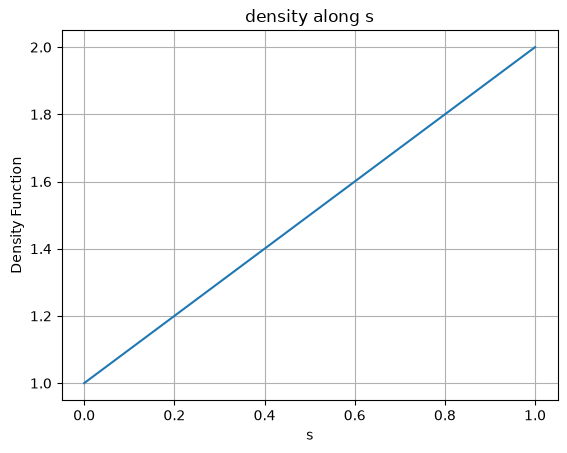

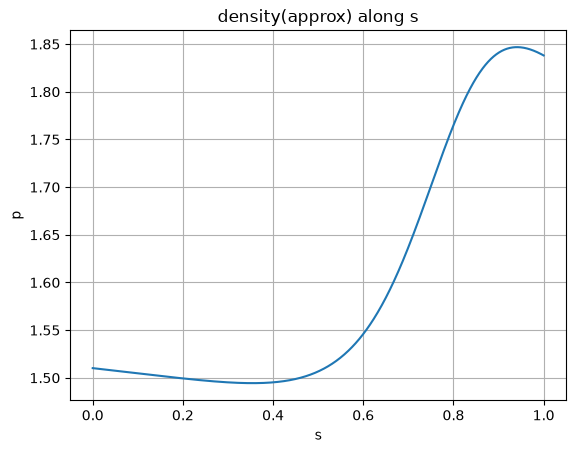

44.4608405805402 0.04441642415638382


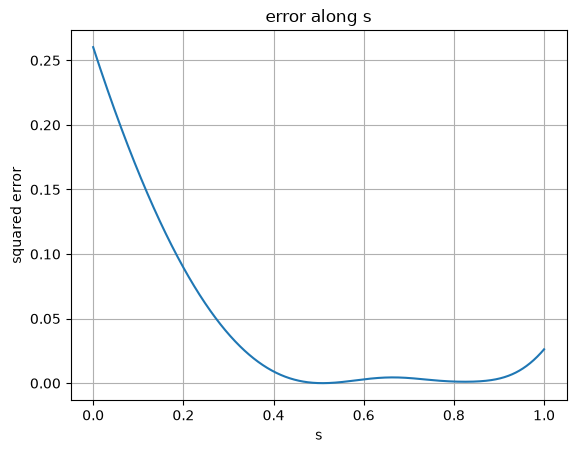

In [33]:

# Density function is 1 +r
# Note: this redefines r WITHOUT real=True, so it is a different SymPy symbol from the r used
# in the solution cell. Harmless here, since this cell only integrates rho.
r = symbols('r')
rho = 1 + r

# Moments of the test density (exact SymPy fractions: mu1 = 5/6, mu2 = 9/20)
mu1 = integrate(rho * r,    (r, 0, 1))   # ∫ ρ r dr
mu2 = integrate(rho * r**3, (r, 0, 1))   # ∫ ρ r³ dr


#Evaluating Density at different values of c1
# Estimated density p(s) = c1*(s)*mu1 + c2*(s)*mu2
# p_vals is the NumPy-array version, df['p'] is the same thing stored in the table.
# Because mu1, mu2 are SymPy numbers, the 'p' column ends up with dtype 'object' rather than float.
p_vals = c1_vals*mu1 + c2_vals*mu2
df['p'] = df['c1']*mu1 + df['c2']*mu2

# Show the full results table
print(df)
# True density at each grid point: p_true(s) = 1 + s
p_true = 1 + s_vals

# Store the true density alongside the estimate
df['p_t'] = p_true

# Spot check at s = 0.5 (index 500 on the 1001-point grid): true vs estimated
print(p_true[500],p_vals[500])


# --- Plot 1: true density ---
plt.plot(df['s'], df['p_t'])
plt.xlabel('s')
plt.ylabel('Density Function')
plt.title('density along s')
plt.grid(True)
plt.show()


# --- Plot 2: estimated density ---
plt.plot(df['s'], df['p'])
plt.xlabel('s')
plt.ylabel('p')
plt.title('density(approx) along s')
plt.grid(True)
plt.show()

# --- Error measures ---
# Pointwise error and squared error at each s
df['error'] = df['p_t'] - df['p']
df['sq_error'] = (df['p_t'] - df['p'])**2

sse  = df['sq_error'].sum()       # sum of squared errors
mse  = df['sq_error'].mean()      # mean squared error

print(sse,mse)

plt.plot(df['s'],df['sq_error'])
plt.xlabel('s')
plt.ylabel('squared error')
plt.title('error along s')
plt.grid(True)
plt.show()
